**CURSO**: Análisis Geoespacial, Departamento de Geociencias y Medio Ambiente, Universidad Nacional de Colombia - sede Medellín <br/>
**Profesor**: Edier Aristizábal (evaristizabalg@unal.edu.co) <br />
**Classroom code**: [32cjlau] <br />
**Créditos**: El contenido de este notebook proviene de varias fuentes: [Patrik Mahadik](https://pratik-mahadik5.medium.com/osmnx-handling-street-networks-6d8a8cbb0628s), [Bryan R. Vallejo](https://towardsdatascience.com/shortest-path-dijkstras-algorithm-step-by-step-python-guide-896769522752). Se ha hecho todo lo posible por identificar a los titulares de los derechos de los materiales usados en este notebook. El autor se disculpa por cualquier omisión involuntaria y con gusto agregará el reconocimiento en futuras ediciones.

# Redes

Desde su lanzamiento en 2005, Google Maps ha sido el principal proveedor de servicios basados en ubicación. Tiene muchas funcionalidades, como imágenes de satélite, datos topográficos en 3D e imágenes a nivel de calle. Sus funciones de rutas y tráfico en vivo ayudan a personas y empresas a tomar mejores decisiones y a planear horarios óptimos.

In [ ]:
from IPython.display import Image
Image(url="https://miro.medium.com/max/600/1*B1EBC7tMLYzT9-pghGyLKw.png")

La API de Google Maps se puede usar en sitios web para mostrar ubicaciones y elementos, y muchas aplicaciones la usan para calcular rutas. Por ejemplo, empresas de domicilios como Swiggy o Zomato usan la API de rutas de Google Maps para entregar comida de forma eficiente en menos tiempo. Pero ese poder tiene un costo: la API de Google Maps es software propietario y su uso es costoso, alrededor de 0 a 10 USD por cada 1000 consultas.

OSM (OpenStreetMap) es un proveedor de mapas impulsado por la comunidad y de código abierto, es decir, de uso libre. Cada persona de la comunidad ayuda a recolectar datos y a alimentar el servidor de mapas de OSM; incluso Google Maps toma datos de OSM para sus servicios. Los datos se actualizan diariamente mediante colaboración abierta y están disponibles gratuitamente para miles de millones de personas.

Estas son algunas API y librerías que usan los datos de la red vial de OSM para calcular rutas y otros servicios:

* OSMnx (Python)
* GraphHopper (JAVA)
* PyrouteLib (Python)
* Openrouteservice (JAVA)
* SimpleOsmRouter (Python)

## OSMnx

[OSMnx](https://osmnx.readthedocs.io/en/stable/osmnx.html) es una librería de Python para analizar datos de redes viales con base en la teoría de grafos. Usa networkx, una librería de Python para estudiar grafos y redes. OSMnx permite descargar datos viales en forma de nodos y aristas, obtenidos de las redes viales de OSM, que luego se pueden modelar y visualizar. Empecemos por instalar la librería e importarla.

In [ ]:
import osmnx as ox

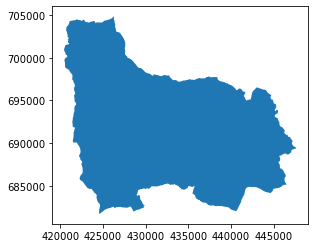

In [ ]:
city = ox.geocode_to_gdf('Medellín, Colombia')
ax = ox.project_gdf(city).plot()

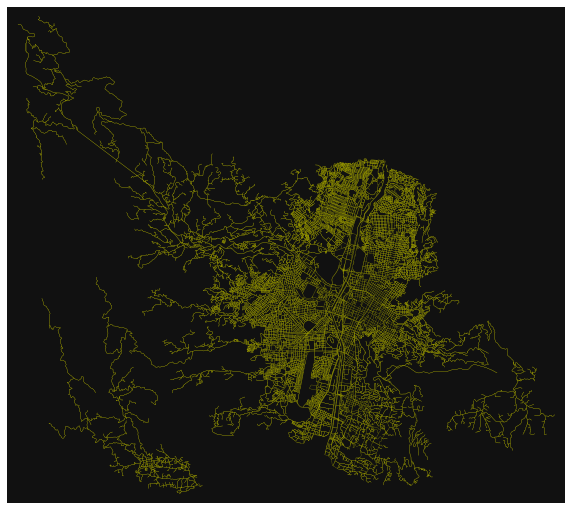

(<Figure size 720x720 with 1 Axes>, <AxesSubplot:>)

In [ ]:
G = ox.graph_from_place('Medellín, Colombia', network_type='drive')
ox.plot_graph(G, figsize=(10, 10), node_size=0, edge_color='y', edge_linewidth=0.2)

Create new dataframe to collect street networks within each voronoi regions

In [ ]:
# obtener todos los parques de un barrio
# constrain acceptable `leisure` tag values to `park`
place = 'Medellín, Colombia'
tags = {'leisure': 'park'}
gdf = ox.geometries_from_place(place, tags)
gdf.head()

,unique_id,osmid,element_type,geometry,name,leisure,description,name:en,tourism,wikidata,...,denomination,surface,opening_hours:covid19,access,dog,note,addr:postcode,ways,fixme,type
0,node/3698821056,3698821056,node,POINT (-75.59766 6.21591),Canalización La Mota,park,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,node/3748104496,3748104496,node,POINT (-75.53658 6.29701),parque,park,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,node/3799873281,3799873281,node,POINT (-75.53896 6.29658),NaN,park,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,node/4177117294,4177117294,node,POINT (-75.54455 6.29402),DE PAN,park,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,node/4177131411,4177131411,node,POINT (-75.54495 6.29082),Parque De La Cancha,park,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# get everything tagged amenity,
# and everything tagged landuse = retail or commercial,
# and everything tagged highway = bus_stop
tags = {'amenity' : True,
        'landuse' : ['retail', 'commercial'],
        'highway' : 'bus_stop'}
gdf = ox.geometries_from_place('Medellín, Colombia', tags)
gdf.shape

/opt/conda/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


(4186, 229)

In [ ]:
# view just the banks
gdf[gdf['amenity']=='bank'].dropna(axis=1, how='any')

/opt/conda/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,unique_id,osmid,element_type,amenity,geometry
3,node/338172348,338172348,node,bank,POINT (-75.57888 6.18369)
139,node/1301957616,1301957616,node,bank,POINT (-75.57338 6.24506)
199,node/1656789265,1656789265,node,bank,POINT (-75.57246 6.20187)
201,node/1657087256,1657087256,node,bank,POINT (-75.57177 6.20652)
205,node/1661049493,1661049493,node,bank,POINT (-75.57395 6.19703)
...,...,...,...,...,...
3591,way/576893946,576893946,way,bank,"POLYGON ((-75.56390 6.25020, -75.56381 6.25037..."
3602,way/578911169,578911169,way,bank,"POLYGON ((-75.57308 6.24206, -75.57301 6.24223..."
3603,way/579013177,579013177,way,bank,"POLYGON ((-75.57333 6.24935, -75.57329 6.24945..."
3617,way/579440533,579440533,way,bank,"POLYGON ((-75.55390 6.30649, -75.55385 6.30648..."


/opt/conda/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


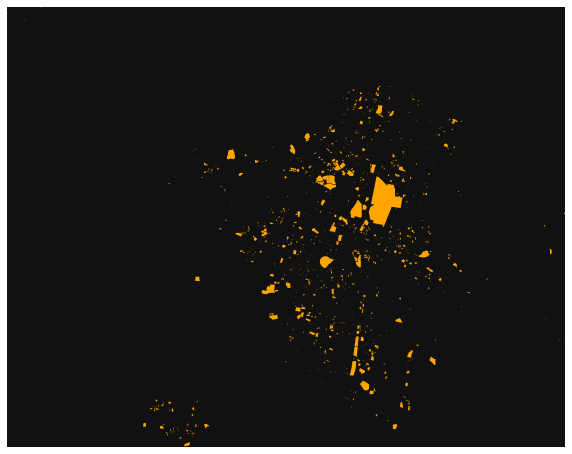

In [ ]:
fig, ax = ox.plot_footprints(gdf, figsize=(10, 10))

In [ ]:
import geopandas as gpd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
location = (6.2159,-75.5976)
mode = "drive"  #Transportation mode
ox.config(log_console=True, use_cache=True)

Empezaremos obteniendo datos a partir de coordenadas de latitud y longitud. Se pueden obtener datos de distintos modos de transporte, como 'walk', 'bike', 'drive', 'drive_service', 'all' o 'all_private'.

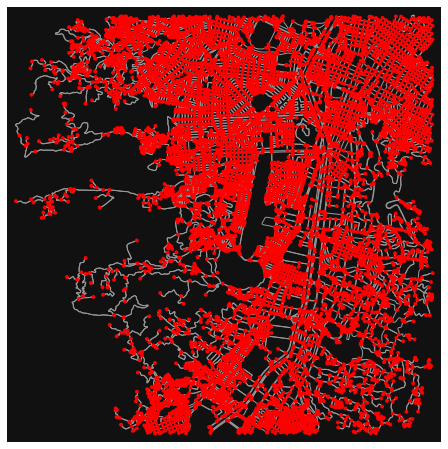

(<Figure size 576x576 with 1 Axes>, <AxesSubplot:>)

In [ ]:
G = ox.graph_from_point(location, dist=5000, simplify=True, network_type=mode)
nodes_proj, edges_proj = ox.graph_to_gdfs(G, nodes=True, edges=True)
ox.plot_graph(G,node_color='r')

Con la función graph_from_point se obtienen los datos de la red vial en forma de nodos y aristas: los nodos son cruces o intersecciones, y las aristas son las líneas (vías) que conectan dos nodos. Se puede especificar la distancia desde la coordenada dada para la que se quieren los datos, y dejar simplify en True para obtener una geometría simplificada. La función plot_graph grafica la red vial, y los nodos se pueden colorear con el parámetro node_color.

### Ruta más corta

Ahora buscaremos la ruta más corta entre dos puntos. Primero se definen el punto de origen y el de destino, y se buscan los nodos más cercanos en el grafo. Luego se usa la función shortest_path para encontrar la ruta más corta. Esta función da una sola ruta; para obtener varias rutas óptimas se usa k_shortest_path, donde el parámetro k indica cuántas rutas se quieren y se puede indicar cualquier columna para usarla como función de peso.

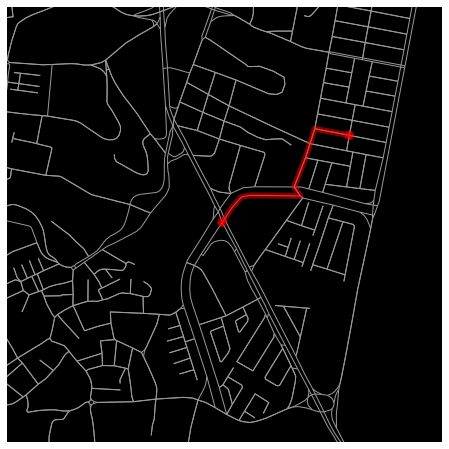

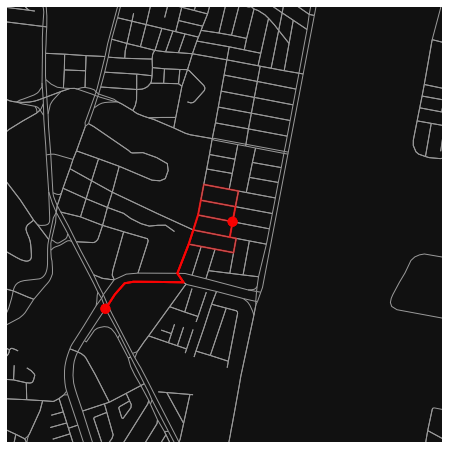

In [ ]:
origin_point = (6.2159,-75.5976)
destination_point =(6.2184,-75.5942)

# obtener los nodos más cercanos a las ubicaciones
origin_node = ox.get_nearest_node(G, origin_point)
destination_node = ox.get_nearest_node(G, destination_point)

route = ox.shortest_path(G, origin_node,destination_node)
bbox = ox.utils_geo.bbox_from_point(point=(6.2159,-75.5976), dist=700)
fig, ax = ox.plot_graph_route(G, route, bbox = bbox, route_linewidth=6, node_size=0, bgcolor='k')

routes = ox.k_shortest_paths(G, origin_node, destination_node, k=5, weight='length')
bbox = ox.utils_geo.bbox_from_point(point=(6.2184,-75.5942), dist=700)
fig, ax = ox.plot_graph_routes(G, list(routes), bbox = bbox, route_colors='r', route_linewidth=2, node_size=0)

### Create Isochrones

/opt/conda/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


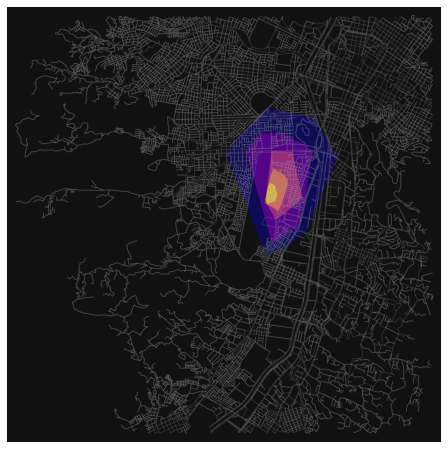

In [ ]:
from shapely.geometry import Point, LineString, Polygon
from descartes import PolygonPatch

# configure the trip times, and travel speed
trip_times = [5, 10, 15, 20, 25] #en minutos
travel_speed = 4.5 #velocidad de caminata en km/h
gdf_nodes = ox.graph_to_gdfs(G, edges=False)
x, y = gdf_nodes['geometry'].unary_union.centroid.xy
center_node = ox.get_nearest_node(G, (y[0], x[0]))

# get one color for each isochrone
iso_colors = ox.plot.get_colors(n=len(trip_times), cmap='plasma', start=0, return_hex=True)

# make the isochrone polygons
isochrone_polys = []
for trip_time in sorted(trip_times, reverse=True):
    subgraph = nx.ego_graph(G, center_node, radius=trip_time, distance='time')
    node_points = [Point((data['x'], data['y'])) for node, data in subgraph.nodes(data=True)]
    bounding_poly = gpd.GeoSeries(node_points).unary_union.convex_hull
    isochrone_polys.append(bounding_poly)

# graficar la red y agregar las isócronas como parches de polígonos coloreados
fig, ax = ox.plot_graph(G, show=False, close=False, edge_color='#999999', edge_alpha=0.2, node_size=0)
for polygon, fc in zip(isochrone_polys, iso_colors):
    patch = PolygonPatch(polygon, fc=fc, ec='none', alpha=0.6, zorder=-1)
    ax.add_patch(patch)
plt.show()

### Ruta de larga distancia
Simplemente crearemos objetos geométricos de tipo punto y luego extraeremos el grafo que usaremos para generar la ruta más corta.

In [3]:
import osmnx as ox
import geopandas as gpd
from shapely.geometry import Point, LineString
import pandas as pd
import matplotlib.pyplot as plt

# origin and destination geom

origin_geom = Point(-5.6613932957355715, 32.93210288339607)

destination_geom = Point(-3.3500597061072726, 34.23038027794419)

# create origin dataframe
origin =  gpd.GeoDataFrame(columns = ['name', 'geometry'], crs = 4326, geometry = 'geometry')
origin.at[0, 'name'] = 'origin'
origin.at[0, 'geometry'] =origin_geom

# create destination dataframe
destination =  gpd.GeoDataFrame(columns = ['name', 'geometry'], crs = 4326, geometry = 'geometry')
destination.at[0, 'name'] = 'destination'
destination.at[0, 'geometry'] = destination_geom

Usaremos la función envelope de Geopandas para usar el polígono como máscara para obtener el grafo.

In [5]:
def get_graph_from_locations(origin, destination, network='drive'):
    '''
    network_type as drive, walk, bike
    origin gdf 4326
    destination gdf 4326
    '''
    # combine and area buffer
    combined = pd.concat([origin, destination])

    convex = combined.unary_union.envelope # se usa envelope en lugar de convex; si no, falla unary_union

    graph_extent = convex.buffer(0.02)

    graph = ox.graph_from_polygon(graph_extent, network_type= network)

    return graph

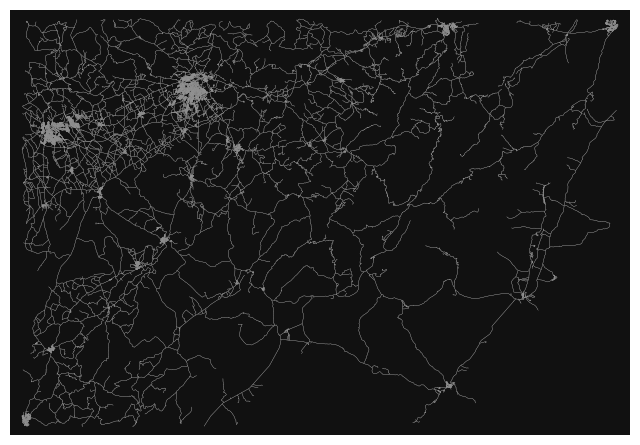

In [6]:
graph = get_graph_from_locations(origin, destination)
fig, ax = ox.plot_graph(graph, node_size=0, edge_linewidth=0.2)

Obtener los nodos más cercanos de la red a partir de las ubicaciones de origen y destino. El código de cada nodo se obtiene con las funciones de osmnx.

In [7]:
# ------------- get closest nodes

# origin
closest_origin_node = ox.nearest_nodes(G=graph,
                                       X=origin_geom.x,
                                       Y=origin_geom.y)

# destination
closest_destination_node = ox.nearest_nodes(G=graph,
                                           X=destination_geom.x,
                                           Y=destination_geom.y)

# run
route = ox.shortest_path(graph,
                         orig = closest_origin_node,
                         dest = closest_destination_node,
                         weight = 'length')

Extraeremos las geometrías de los nodos del grafo y crearemos una geometría LineString que represente la ruta más corta

In [8]:
def nodes_to_route(graph_nodes, path_nodes):

    # Extraer los nodos de la ruta en el grafo
    route_nodes = graph_nodes.loc[path_nodes]

    # ---> ¡atención! Si tiene más rutas, revise cada una y elimine las de longitud 1: no se puede construir una ruta con un solo nodo.

    # Create a LineString out of the route
    list_geom = route_nodes.geometry.to_list()
    path = LineString(list_geom)

    # Agregar el resultado al GeoDataFrame
    route_df = gpd.GeoDataFrame( [[path]] )

    # Add a column name
    route_df.columns = ['geometry']

    # Set geometry
    route_df = route_df.set_geometry('geometry')

    # Set coordinate reference system
    route_df.crs = graph_nodes.crs

    # remove nans
    route_df = route_df.dropna(subset=['geometry'])

    return route_df

In [9]:
# get all network nodes
graph_nodes = ox.graph_to_gdfs(graph, edges=False)

# get the line geometries from osm nodes
route_gdf = nodes_to_route(graph_nodes, route)

Mediremos la ruta en metros con una proyección Mercator. Puede usar la proyección local si quiere un resultado más preciso.

In [10]:
def compute_distance(shortest_path_gdf):
    '''
    Compute distance in EPSG:3387

    '''

    # project WGS84 to EPSG3387
    distances = shortest_path_gdf.to_crs("EPSG:3387").geometry.length

    # add
    shortest_path_gdf['distance'] = distances

    return shortest_path_gdf

In [13]:
# calculate distance m
route_distance_gdf = compute_distance(route_gdf)
route_distance_gdf

,geometry,distance
0,"LINESTRING (-5.66184 32.93275, -5.66244 32.932...",351243.958791


Guardar en el disco local la red y la ruta para los mapas.

Obtener la red y definir el GeoDataFrame:

In [12]:
# fetch network
network = ox.graph_to_gdfs(graph, nodes=False)

# get only needed columns
network_gdf = network.reset_index(drop=True)[['geometry']]

network_gdf.to_file(r'osm_network.gpkg')
route_distance_gdf.to_file(r'osm_shortest_path.gpkg')

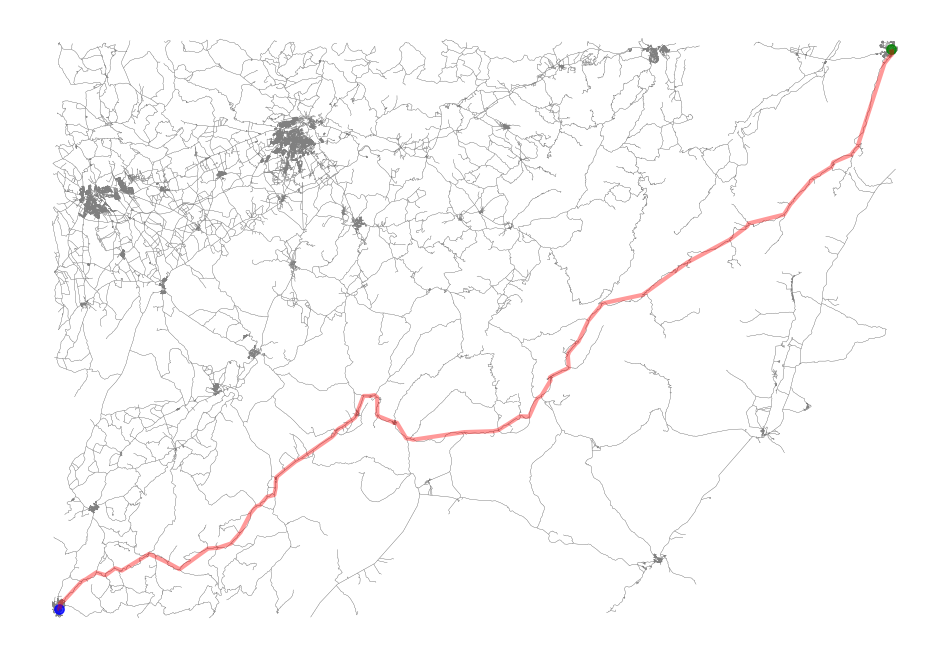

In [14]:
# plot network
ax = network_gdf.plot(figsize=(12, 10), linewidth = 0.2, color='grey', zorder=0);

# origin and destination
origin.plot(ax=ax, markersize=46, alpha=0.8, color='blue', zorder=1)
destination.plot(ax=ax, markersize=46, alpha=0.8, color='green', zorder=2)

# route
route_distance_gdf.plot(ax=ax, linewidth = 3, color='red', alpha=0.4, zorder=3)

plt.axis(False);

### Highlight Oneway Roads

Para visualizar las vías de un solo sentido podemos usar la columna oneway de las aristas. Aquí se muestran en rojo las vías de un solo sentido y en blanco las demás.

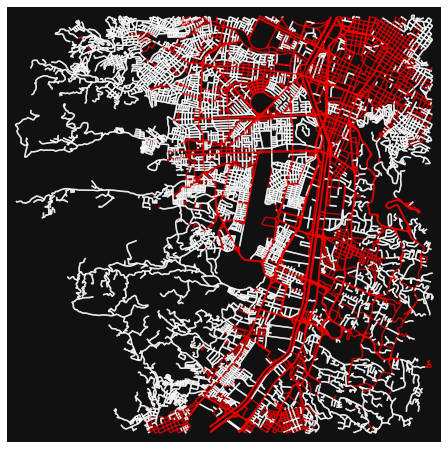

In [ ]:
ec = ['r' if data['oneway'] else 'w' for u, v, key, data in G.edges(keys=True, data=True)]
fig, ax = ox.plot_graph(G, node_size=0, edge_color=ec, edge_linewidth=1.5, edge_alpha=0.7)

### Steet centrality colour gradient

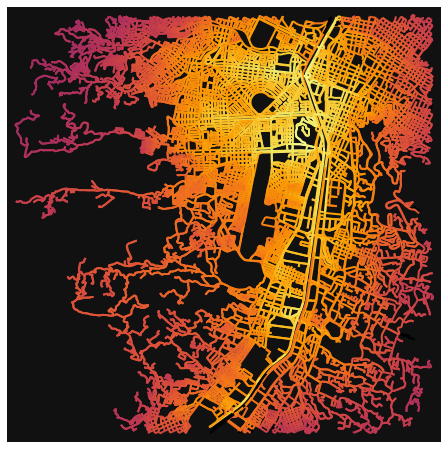

In [ ]:
# convert graph to line graph so edges become nodes and vice versa
edge_centrality = nx.closeness_centrality(nx.line_graph(G))
nx.set_edge_attributes(G, edge_centrality, 'edge_centrality')

# colorear las aristas del grafo original con la centralidad de cercanía del grafo de líneas
ec = ox.plot.get_edge_colors_by_attr(G, 'edge_centrality', cmap='inferno')
fig, ax = ox.plot_graph(G, edge_color=ec, edge_linewidth=2, node_size=0)

### Graficar rutas en folium
Para graficar rutas y redes viales en folium se usan las funciones plot_graph_folium y plot_route_folium. Primero tomamos un nodo de origen y uno de destino del grafo obtenido del servidor de OSM y buscamos la ruta más corta entre ellos. Al crear el grafo y la ruta en folium se puede indicar qué columna usar en las ventanas emergentes. El mapa web se puede guardar como página html para compartirlo.

In [ ]:
origin_node = list(G.nodes())[0]
destination_node = list(G.nodes())[-1]
route = nx.shortest_path(G, origin_node, destination_node)
graph_map = ox.plot_graph_folium(G, popup_attribute='name', edge_width=2)
route_graph_map = ox.plot_route_folium(G, route, route_map=graph_map, popup_attribute='length')
route_graph_map.save('route.html')
route_graph_map

### Guardar los datos de la red
Los datos de la red vial descargados se pueden guardar en varios formatos, como geopackage o shp, para usarlos en software SIG. También se pueden guardar como imagen svg o como archivo graphml.

In [ ]:
ox.save_graph_geopackage(G, filepath='./data/street_network.gpkg')
ox.save_graphml(G, filepath='./data/street_network.graphml')
ox.save_graph_shapefile(G, filepath='./data/streets')
ox.plot_graph(G, show=False, save=True, close=True, filepath='./images/street_network.svg')
ox.save_graph_xml(G, filepath='./data/street_network.osm')

/opt/conda/lib/python3.8/site-packages/osmnx/osm_xml.py:181: UserWarning: In order for save_graph_xml to behave properly the graph must have been created with the `all_oneway` setting set to True.
  warnings.warn(msg)
